In [1]:
# Jax
import jax
# Jax's specialized numpy library
import jax.numpy as jnp
# Neural Network Library
import flax.nnx as nnx

import matplotlib.pyplot as plt

In [2]:
class TokenAndPositionEmbedding(nnx.Module):
    def __init__(self, maxlen, vocab_size, embed_dim, *, rngs):
        # Token Embedding
        # Letting the model learn the embedding
        self.token_emb = nnx.Embed(vocab_size, embed_dim, rngs=rngs)
        # Position Embedding
        # Allows the transform to know the order of the tokens
        # Letting the model learn the embedding
        self.pos_emb = nnx.Embed(maxlen, embed_dim, rngs=rngs)

    def __call__(self, x):
        seq_len = x.shape[1]
        positions = jnp.arange(seq_len)[None, :]
        return self.token_emb(x) + self.pos_emb(positions)

In [3]:
def causal_attention_mask(seq_len):
    # Triangular Matrix full of ones
    # Allows the LLM to only look backwards and not forwards
    return jnp.tril(jnp.ones((seq_len, seq_len)))

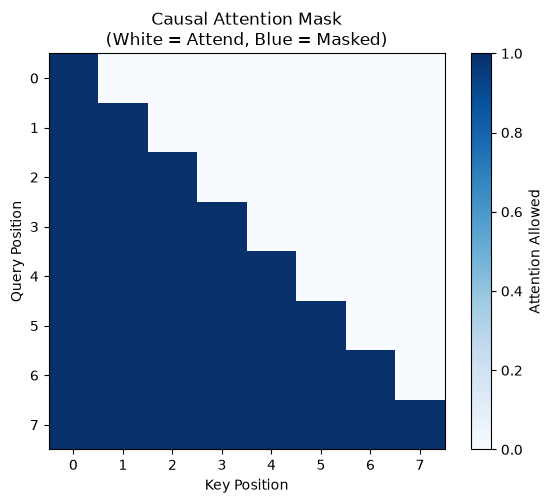

In [4]:
mask = causal_attention_mask(8)
plt.figure(figsize=(6, 5))
plt.imshow(mask, cmap='Blues', interpolation='nearest')
plt.xlabel('Key Position')
plt.ylabel('Query Position')
plt.title('Causal Attention Mask\n(White = Attend, Blue = Masked)')
plt.colorbar(label='Attention Allowed')
plt.tight_layout()
plt.show()

In [5]:
class TransformerBlock(nnx.Module):

    def __init__(self, embed_dim, num_heads, ff_dim, *, rngs):
        # Missing:
        # Normalization Layer
        # Feed forward network

        # The "experts" that keep track of things such as plot, characters, etc
        self.attention = nnx.MultiHeadAttention(
            num_heads=num_heads,
            in_features=embed_dim,
            qkv_features=embed_dim,
            out_features=embed_dim,
            decode=False,
            rngs=rngs
        )
        
    def __call__(self, x, mask=None):
        attn_out = self.attention(x, mask=mask)
        # Residual Connections
        # Allows LLM to skip over some of the heads as it sees fit
        # Allows for faster and more stable learning and keeps the gradients in check
        x = x + attn_out
        return x

In [6]:
class MiniGPT(nnx.Module):

    def __init__(self, maxlen, vocab_size, embed_dim, num_heads,
                 feed_forward_dim, num_transformer_blocks, *, rngs):
        self.maxlen = maxlen
        self.embedding = TokenAndPositionEmbedding(maxlen, vocab_size, 
                                                   embed_dim, rngs=rngs)
        self.transformer_blocks = nnx.List([
            TransformerBlock(embed_dim, num_heads, feed_forward_dim, 
                             rngs=rngs)
            for _ in range(num_transformer_blocks)
        ])
        self.output_layer = nnx.Linear(embed_dim, vocab_size, 
                                       use_bias=False, rngs=rngs)
        
    def causal_attention_mask(self, seq_len):
        return jnp.tril(jnp.ones((seq_len, seq_len)))

    def __call__(self, token_ids):
        seq_len = token_ids.shape[1]
        mask = self.causal_attention_mask(seq_len)
        x = self.embedding(token_ids)
        for block in self.transformer_blocks:
            x = block(x, mask=mask)

        logits = self.output_layer(x)
        return logits

In [7]:
# The token scheme for the model
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
tokenizer.n_vocab

50257

In [8]:
model = MiniGPT(
    maxlen=128,
    vocab_size=tokenizer.n_vocab,
    embed_dim=192,
    num_heads=6,
    feed_forward_dim = 512,
    num_transformer_blocks=6,
    rngs=nnx.Rngs(0)
)

In [9]:
# model

In [10]:
# Data Loading goes in the following steps
# 1. Tokeninzing the text
# 2. Input-target pairs
# 3. Batching

# Data Loading will use Grain as it is part of the JAX AI stack
# Lazy Loads data into batches to keeps the computer running smooth

In [11]:
import grain.python as grain
from pathlib import Path
from helper import load_stories_from_file

In [12]:
file_path = Path("TinyStories-1000.txt")

with open(file_path, 'r', encoding='utf-8', errors='replace') as f:
    data = f.read()
    stories = data.split('<|endoftext|>')

    print("First story (300 chars):\n")
    story = stories[0]
    print(story.strip()[:300], "...")

    print(f"\nTotal number of stories: {len(stories) - 1:,}")


First story (300 chars):

One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.
Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and s ...

Total number of stories: 1,000


In [13]:
# Tiktoken has more tokenization schemes that include things beyond endoftext to help better break up the material
tokenizer = tiktoken.get_encoding("gpt2")

print(f"Vocabulary size: {tokenizer.n_vocab:,}")
print(f"Special tokens: {tokenizer.special_tokens_set}")

Vocabulary size: 50,257
Special tokens: {'<|endoftext|>'}


In [14]:
class StoryDataset:
    
    def __init__(self, stories, maxlen, tokenizer):
        self.stories = stories
        self.maxlen = maxlen
        self.tokenizer = tokenizer
        self.end_token = tokenizer.encode('<|endoftext|>', \
                        allowed_special={'<|endoftext|>'})[0]

    def __len__(self):
        return len(self.stories)

    def __getitem__(self, idx):
        story = self.stories[idx]
        tokens = self.tokenizer.encode(story, 
                                       allowed_special={'<|endoftext|>'})

        # Cutting the story if it is too long
        if len(tokens) > self.maxlen:
            tokens = tokens[:self.maxlen]

        # Padding if the story is too short.
        # ALL STORIES MUST BE THE SAME SIZE
        tokens.extend([0] * (self.maxlen - len(tokens)))
        return tokens

In [15]:
# Shuffle the data to avoid training artifacts
shuffled_sampler = grain.IndexSampler(
    num_records=10,
    shuffle=True,
    seed=42,
    shard_options=grain.NoSharding(),    
    num_epochs=1
)

def print_sampler_example(sampler, name):
    print(f"\n{name}")
    for i, idx in enumerate(sampler):
        print(f"Record {i}: {idx}")

print_sampler_example(shuffled_sampler, "Shuffled sampler")



Shuffled sampler
Record 0: RecordMetadata(index=0, record_key=8, rng=Generator(Philox))
Record 1: RecordMetadata(index=1, record_key=6, rng=Generator(Philox))
Record 2: RecordMetadata(index=2, record_key=7, rng=Generator(Philox))
Record 3: RecordMetadata(index=3, record_key=9, rng=Generator(Philox))
Record 4: RecordMetadata(index=4, record_key=0, rng=Generator(Philox))
Record 5: RecordMetadata(index=5, record_key=5, rng=Generator(Philox))
Record 6: RecordMetadata(index=6, record_key=1, rng=Generator(Philox))
Record 7: RecordMetadata(index=7, record_key=2, rng=Generator(Philox))
Record 8: RecordMetadata(index=8, record_key=4, rng=Generator(Philox))
Record 9: RecordMetadata(index=9, record_key=3, rng=Generator(Philox))


In [16]:
# Batcher
batch_op_stories = load_stories_from_file(
    "TinyStories-1000.txt", 
    max_stories=100
)
keep = grain.Batch(
    batch_size=32,
    drop_remainder=False
)

Loading stories from TinyStories-1000.txt...
Loaded 100 stories


In [17]:
def create_dataloader(
    stories,
    tokenizer,
    maxlen,
    batch_size,
    shuffle = False,
    num_epochs = 1,
    seed = 42,
    worker_count = 0
):
    dataset = StoryDataset(stories, maxlen, tokenizer)
    estimated_batches = len(dataset) // batch_size

    sampler = grain.IndexSampler(
        num_records=len(dataset), # 1,000 stories for this dataset
        shuffle=shuffle,
        seed=seed,
        shard_options=grain.NoSharding(),
        num_epochs=num_epochs
    )
    dataloader = grain.DataLoader(
        data_source=dataset,
        sampler=sampler,
        operations=[
            grain.Batch(batch_size=batch_size, drop_remainder=True)
        ],
        worker_count=worker_count
    )
    
    return dataloader, estimated_batches

In [18]:
stories = load_stories_from_file(
    "TinyStories-1000.txt", 
    max_stories=100
)

Loading stories from TinyStories-1000.txt...
Loaded 100 stories


In [19]:
dataloader, batches_per_epoch = create_dataloader(
    stories=stories,
    tokenizer=tokenizer,
    maxlen=128,
    batch_size=32,
    shuffle=False,
    num_epochs=1,
    seed=42,
    worker_count=0  # Single process for experimentation
)

print(f"\nDataLoader created successfully:")
print(f"Will produce {batches_per_epoch} batches per epoch")


DataLoader created successfully:
Will produce 3 batches per epoch


In [20]:
# Optax is the gradient based optimization library for JAX
# Orbax is for checking pointing the training so it can be run across different machines

In [21]:
import jax
import jax.numpy as jnp
import flax.nnx as nnx
import grain.python as pygrain
import tiktoken

import optax

In [22]:
from helper import load_and_preprocess_data, generate_text

In [51]:
maxlen=128
tokenizer = tiktoken.get_encoding("gpt2")

In [52]:
text_dl, batches_per_epoch = load_and_preprocess_data(
    file_path='TinyStories-1000.txt',
    batch_size=32,
    maxlen=maxlen,
    max_stories=100,
    shuffle=True,
    seed=42
)

Loading data from TinyStories-1000.txt (max 100 stories)
Loaded 100 stories
Estimated batches per epoch: 3
Created DataLoader with batch_size=32, maxlen=200


In [53]:
def loss_fn(model, batch):
    inputs, targets = batch
    logits = model(inputs)
    loss = optax.softmax_cross_entropy_with_integer_labels(
        logits, targets
    ).mean()
    return loss, logits

In [54]:
num_epochs=3
total_steps = batches_per_epoch * num_epochs
warmup_steps = max(1, total_steps // 10)  # 10% warmup
print(f"Total training steps: {total_steps:,}")
print(f"Warmup steps: {warmup_steps:,}")

Total training steps: 9
Warmup steps: 1


In [55]:
lr_schedule = optax.warmup_cosine_decay_schedule(
    init_value=0.0,
    peak_value=3e-4,
    warmup_steps=warmup_steps,
    decay_steps=total_steps,
    end_value=1e-5
)

In [56]:
optimizer = nnx.ModelAndOptimizer(
    model,
    optax.adamw(learning_rate=lr_schedule, weight_decay=0.01)
)

In [57]:
metrics = nnx.MultiMetric(
    loss=nnx.metrics.Average('loss'),
)

In [58]:
@nnx.jit
def train_step(model, optimizer, metrics, batch):
    grad_fn = nnx.value_and_grad(loss_fn, has_aux=True)
    (loss, logits), grads = grad_fn(model, batch)

    metrics.update(loss=loss, logits=logits, labels=batch[1])
    optimizer.update(grads)

In [59]:
metrics_history = {'train_loss': []}

prep_target_batch = jax.vmap(
    lambda tokens: jnp.concatenate((tokens[1:], jnp.array([0]))))

for epoch in range(num_epochs):
    step = 0
    for batch in text_dl:
        input_batch = jnp.array(jnp.array(batch).T).astype(jnp.int32)
        target_batch = prep_target_batch(
            jnp.array(jnp.array(batch).T)).astype(jnp.int32)
        print(".", end="")
        train_step(model, optimizer, metrics, (input_batch, target_batch))

        if (step + 1) % 2 == 0:
            for metric, value in metrics.compute().items():
                metrics_history[f'train_{metric}'].append(value)
            metrics.reset()

            current_lr = lr_schedule(step)
            print(f"\nEpoch: {epoch + 1}, Step {step + 1}, Loss: {metrics_history['train_loss'][-1]:.4f}, "
                  f"LR: {current_lr:.2e}")
        step += 1

..
Epoch: 1, Step 2, Loss: nan, LR: 3.00e-04
...
Epoch: 2, Step 2, Loss: nan, LR: 3.00e-04
...
Epoch: 3, Step 2, Loss: nan, LR: 3.00e-04
.

In [ ]:
import matplotlib.pyplot as plt
plt.plot(metrics_history['train_loss'])
plt.title('Training Loss — 3 steps, 1000 stories')
plt.xlabel('Step')
plt.ylabel('Loss')
plt.show()

In [ ]:
from pathlib import Path
import orbax

checkpoint_path = Path.cwd() / "small_checkpoint.orbax"

checkpointer = orbax.checkpoint.PyTreeCheckpointer()

checkpointer.save(checkpoint_path, nnx.state(model), force=True)
print(f"Model saved as {checkpoint_path}")

In [ ]:
import jax
import flax.nnx as nnx
from pathlib import Path

from helper import MiniGPT, generate_story

In [ ]:
model = MiniGPT()

In [ ]:
#model

In [ ]:
import orbax
from orbax import checkpoint

from jax.sharding import SingleDeviceSharding 

In [ ]:
cpu_device = jax.devices('cpu')[0]
cpu_sharding = SingleDeviceSharding(cpu_device)

In [ ]:
restore_args = jax.tree_util.tree_map(
    lambda _: checkpoint.ArrayRestoreArgs(sharding=cpu_sharding),
    nnx.state(model)
)

In [ ]:
#nnx.state(model)

In [ ]:
checkpoint_path = Path.cwd() / "small_checkpoint.orbax"
checkpointer = orbax.checkpoint.PyTreeCheckpointer()

In [ ]:
restored_state = checkpointer.restore(
    checkpoint_path,
    item=nnx.state(model),
    restore_args=restore_args)

nnx.update(model,restored_state)

In [ ]:
def create_story(story_prompt, temperature, max_new_tokens):
    return generate_story(model, story_prompt, temperature, max_new_tokens)

In [ ]:
create_story("Once", 0.2, 30)

In [ ]:
# import gradio as gr

# demo = gr.Interface(
#     fn=create_story,
#     inputs=[
#         gr.Textbox(label="Story Prompt"),         
#         gr.Slider(
#             minimum=0, maximum=1.0, value=0.8, step=0.01, label="Temperature"
#         ),
#         gr.Slider(minimum=0, maximum=200, value=10, step=1, label="Max Tokens"
#         )
#     ],
#     outputs=["text"]
# )

# demo.launch(share=True)